# Statistical Analysis of Oxygen and Nitrate Concentrations Across River Sections and Seasons

Application Report

M.Sc. Data Science – Summer Semester 2027

TU Dortmund University

Submitted by: Ahmed Nabil Mohamed Badr Rakha

Email: theahmednabil2003@gmail.com

Date: 11 November 2026

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Data Loading and Exploration

In [2]:
df = pd.read_csv("waterquality.csv", sep=";")

In [3]:
df

,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245
...,...,...,...,...,...
895,896,A5_mouth,winter,9.354,11.251
896,897,A5_mouth,winter,8.300,10.467
897,898,A5_mouth,winter,6.644,9.094
898,899,A5_mouth,winter,10.772,9.427


In [4]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(900, 5)
ID                 int64
river_section     object
saison            object
nitrate_mgL      float64
oxygen_mgL       float64
dtype: object
ID               0
river_section    0
saison           0
nitrate_mgL      0
oxygen_mgL       0
dtype: int64


In [5]:
print(pd.crosstab(df["river_section"], df["saison"]))

saison            autumn  spring  summer  winter
river_section                                   
A1_headwaters         45      45      45      45
A2_upper_course       45      45      45      45
A3_middle_course      45      45      45      45
A4_lower_course       45      45      45      45
A5_mouth              45      45      45      45


## Descriptive Statistics


In [6]:
print(df[["nitrate_mgL", "oxygen_mgL"]].describe())

       nitrate_mgL  oxygen_mgL
count   900.000000  900.000000
mean      8.811672    8.971169
std       2.873274    1.425223
min       1.510000    4.608000
25%       6.762250    8.057500
50%       8.887000    9.263500
75%      10.926750    9.979000
max      16.444000   12.167000


In [7]:
print(df.groupby("saison")["nitrate_mgL"].describe())
print(df.groupby("saison")["oxygen_mgL"].describe())

        count       mean       std    min    25%     50%     75%     max
saison                                                                  
autumn  225.0   8.418182  2.752180  1.999  6.627   8.568  10.510  16.377
spring  225.0   9.288844  2.590759  1.510  7.176   9.652  11.215  14.786
summer  225.0  10.341880  2.744214  3.963  8.357  10.708  12.525  16.444
winter  225.0   7.197782  2.442061  1.562  5.287   7.552   8.943  13.211
        count      mean       std    min    25%    50%     75%     max
saison                                                                
autumn  225.0  9.378876  0.887774  6.613  8.742  9.514  10.007  12.107
spring  225.0  9.530813  0.856994  7.479  8.976  9.550  10.129  12.167
summer  225.0  7.040329  0.929590  4.608  6.348  6.975   7.759   9.809
winter  225.0  9.934658  0.778923  7.703  9.427  9.872  10.400  12.029


In [8]:
print(df.groupby("river_section")["nitrate_mgL"].describe())
print(df.groupby("river_section")["oxygen_mgL"].describe())

                  count       mean       std    min       25%      50%  \
river_section                                                            
A1_headwaters     180.0   5.350394  1.708003  1.510   4.02625   5.3535   
A2_upper_course   180.0   7.342933  1.788534  3.732   6.27275   7.2220   
A3_middle_course  180.0   9.328411  1.809493  4.061   8.00125   9.4910   
A4_lower_course   180.0  10.570044  1.857924  6.328   9.22100  10.4505   
A5_mouth          180.0  11.466578  1.984582  6.644  10.16675  11.3975   

                       75%     max  
river_section                       
A1_headwaters      6.65750  11.053  
A2_upper_course    8.59000  12.363  
A3_middle_course  10.64200  13.095  
A4_lower_course   12.08825  15.362  
A5_mouth          13.01300  16.444  
                  count      mean       std    min      25%     50%       75%  \
river_section                                                                   
A1_headwaters     180.0  9.230817  1.229792  6.199  8.46900 

## Plots


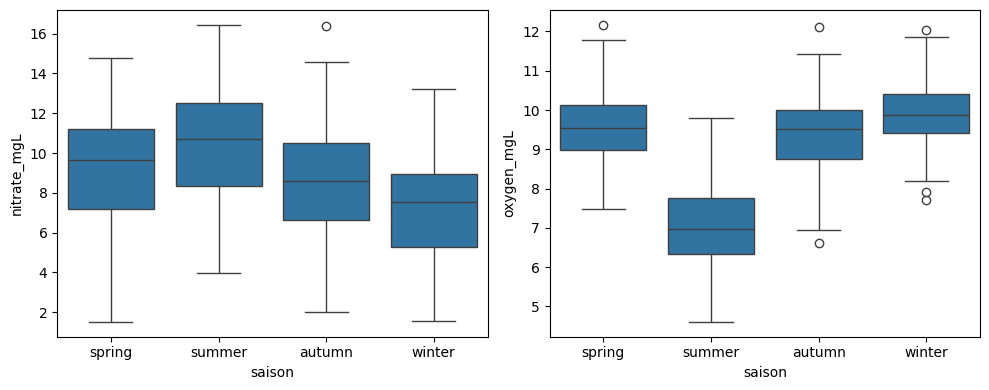

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(x="saison", y="nitrate_mgL", data=df, ax=axes[0])
sns.boxplot(x="saison", y="oxygen_mgL", data=df, ax=axes[1])

plt.tight_layout()
plt.show()

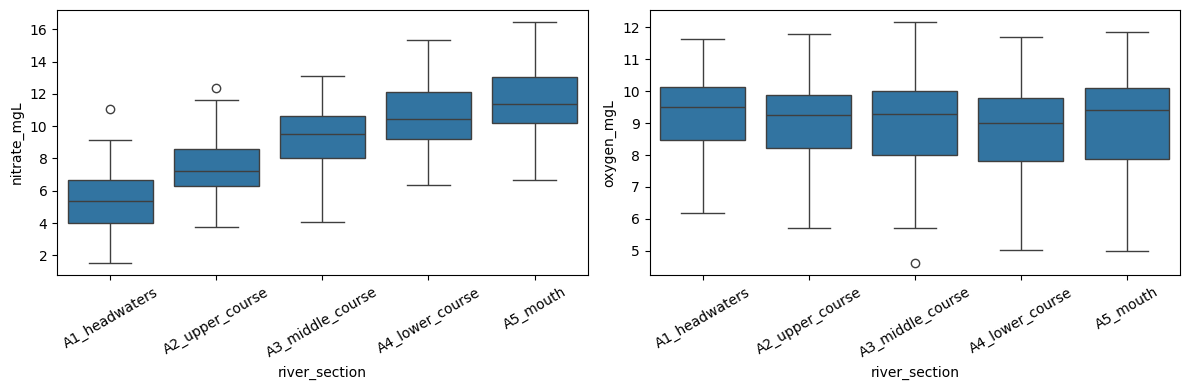

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x="river_section", y="nitrate_mgL", data=df, ax=axes[0])
sns.boxplot(x="river_section", y="oxygen_mgL", data=df, ax=axes[1])

axes[0].tick_params(axis="x", rotation=30)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Comparison of Oxygen and Nitrate Concentrations Between Spring and Autumn
First we check normality (Shapiro-Wilk) and equal variances (Levene) in both seasons.

In [11]:
spring = df[df["saison"] == "spring"]
autumn = df[df["saison"] == "autumn"]

for i in ["nitrate_mgL", "oxygen_mgL"]:
    print(i)
    print("Shapiro spring:", stats.shapiro(spring[i]))
    print("Shapiro autumn:", stats.shapiro(autumn[i]))
    print("Levene:", stats.levene(spring[i], autumn[i]))
    print()

nitrate_mgL
Shapiro spring: ShapiroResult(statistic=np.float64(0.9853919877010259), pvalue=np.float64(0.02062424434623139))
Shapiro autumn: ShapiroResult(statistic=np.float64(0.9850272703672933), pvalue=np.float64(0.017948161005734372))
Levene: LeveneResult(statistic=np.float64(1.5601062573063793), pvalue=np.float64(0.21230189879299693))

oxygen_mgL
Shapiro spring: ShapiroResult(statistic=np.float64(0.9940458843192658), pvalue=np.float64(0.5144426324468645))
Shapiro autumn: ShapiroResult(statistic=np.float64(0.9891810769589149), pvalue=np.float64(0.08914464599628459))
Levene: LeveneResult(statistic=np.float64(0.6629190600535767), pvalue=np.float64(0.4159638518950779))



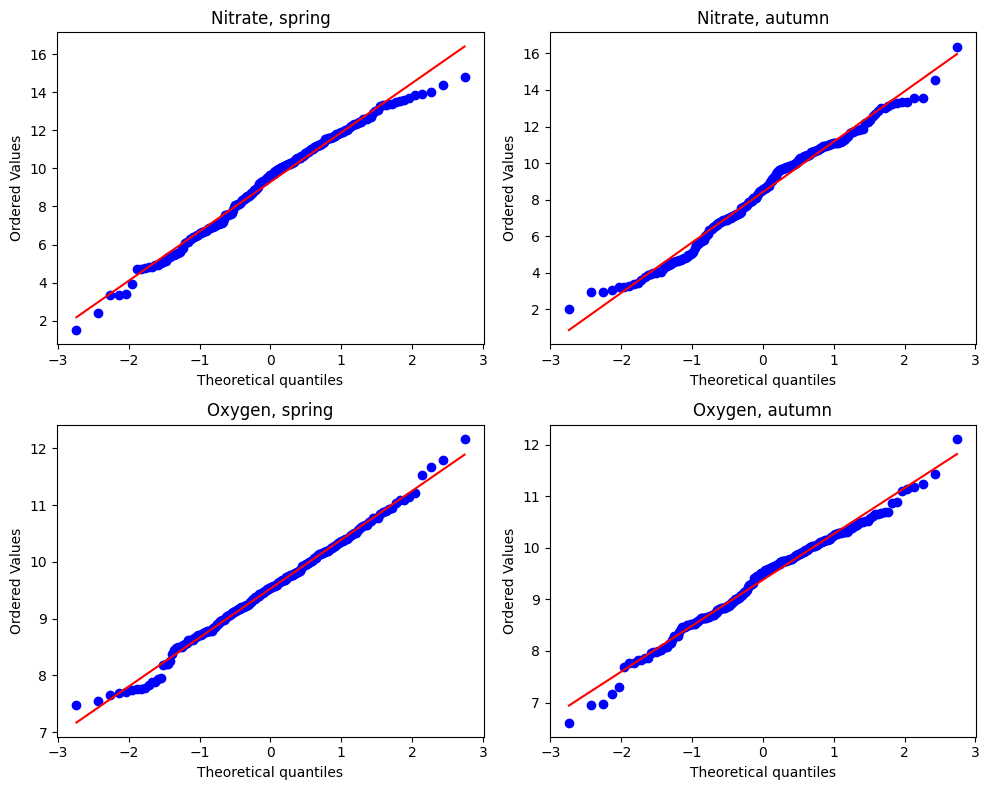

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

stats.probplot(spring["nitrate_mgL"], plot=axes[0, 0])
stats.probplot(autumn["nitrate_mgL"], plot=axes[0, 1])
stats.probplot(spring["oxygen_mgL"], plot=axes[1, 0])
stats.probplot(autumn["oxygen_mgL"], plot=axes[1, 1])

axes[0, 0].set_title("Nitrate, spring")
axes[0, 1].set_title("Nitrate, autumn")
axes[1, 0].set_title("Oxygen, spring")
axes[1, 1].set_title("Oxygen, autumn")

plt.tight_layout()
plt.show()

Oxygen is normal with equal variances, so we use the t-test. For nitrate the Shapiro p-values are just below 0.05, so we use the Mann-Whitney U test

In [13]:
# oxygen: normal and equal variances -> t-test
print(stats.ttest_ind(spring["oxygen_mgL"], autumn["oxygen_mgL"]))

# nitrate: Shapiro p < 0.05 -> Mann-Whitney
print(stats.mannwhitneyu(spring["nitrate_mgL"], autumn["nitrate_mgL"]))

TtestResult(statistic=np.float64(1.8469991514452557), pvalue=np.float64(0.06540647841673818), df=np.float64(448.0))
MannwhitneyuResult(statistic=np.float64(29947.5), pvalue=np.float64(0.0007797818094638763))


## Comparison of Oxygen and Nitrate Concentrations Across River Sections

In [14]:
sections = df["river_section"].unique()

for i in ["nitrate_mgL", "oxygen_mgL"]:
    print(i)
    groups = [df[df["river_section"] == s][i] for s in sections]
    for s, g in zip(sections, groups):
        print("Shapiro", s, stats.shapiro(g))
    print("Levene:", stats.levene(*groups))
    print()

nitrate_mgL
Shapiro A1_headwaters ShapiroResult(statistic=np.float64(0.989597317387788), pvalue=np.float64(0.2128793329437333))
Shapiro A2_upper_course ShapiroResult(statistic=np.float64(0.987795088979907), pvalue=np.float64(0.12259281890396384))
Shapiro A3_middle_course ShapiroResult(statistic=np.float64(0.9865156839540724), pvalue=np.float64(0.08222414186819967))
Shapiro A4_lower_course ShapiroResult(statistic=np.float64(0.9881488990604469), pvalue=np.float64(0.13680236348395186))
Shapiro A5_mouth ShapiroResult(statistic=np.float64(0.9910395703306102), pvalue=np.float64(0.32458532037354315))
Levene: LeveneResult(statistic=np.float64(1.0973749342114285), pvalue=np.float64(0.35656630885357216))

oxygen_mgL
Shapiro A1_headwaters ShapiroResult(statistic=np.float64(0.9725087092369185), pvalue=np.float64(0.00126180834233948))
Shapiro A2_upper_course ShapiroResult(statistic=np.float64(0.9600983145678035), pvalue=np.float64(5.3731467007283794e-05))
Shapiro A3_middle_course ShapiroResult(stat

Nitrate passes both checks, so we use ANOVA. Oxygen fails both, so we use Kruskal-Wallis.

In [15]:
nitrate = [df[df["river_section"] == s]["nitrate_mgL"] for s in sections]
oxygen = [df[df["river_section"] == s]["oxygen_mgL"] for s in sections]

print(stats.f_oneway(*nitrate))
print(stats.kruskal(*oxygen))

F_onewayResult(statistic=np.float64(329.10372246517767), pvalue=np.float64(4.246425146083035e-174))
KruskalResult(statistic=np.float64(11.645112856578162), pvalue=np.float64(0.02019496054213179))


Post-hoc for nitrate: Tukey HSD compares all pairs of sections and corrects for the multiple comparisons itself.

In [16]:
print(stats.tukey_hsd(*nitrate))

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -1.993     0.000    -2.520    -1.465
 (0 - 2)     -3.978     0.000    -4.506    -3.450
 (0 - 3)     -5.220     0.000    -5.747    -4.692
 (0 - 4)     -6.116     0.000    -6.644    -5.588
 (1 - 0)      1.993     0.000     1.465     2.520
 (1 - 2)     -1.985     0.000    -2.513    -1.458
 (1 - 3)     -3.227     0.000    -3.755    -2.699
 (1 - 4)     -4.124     0.000    -4.651    -3.596
 (2 - 0)      3.978     0.000     3.450     4.506
 (2 - 1)      1.985     0.000     1.458     2.513
 (2 - 3)     -1.242     0.000    -1.769    -0.714
 (2 - 4)     -2.138     0.000    -2.666    -1.610
 (3 - 0)      5.220     0.000     4.692     5.747
 (3 - 1)      3.227     0.000     2.699     3.755
 (3 - 2)      1.242     0.000     0.714     1.769
 (3 - 4)     -0.897     0.000    -1.424    -0.369
 (4 - 0)      6.116     0.000     5.588     6.644
 (4 - 1)      4.124     0.000   

Post-hoc for oxygen: Mann-Whitney for every pair of sections (10 pairs). The p-values are multiplied by 10 (Bonferroni) and capped at 1, so they can be compared with 0.05 directly.

In [17]:
from itertools import combinations

for a, b in combinations(range(5), 2):
    res = stats.mannwhitneyu(oxygen[a], oxygen[b])
    print(sections[a], "vs", sections[b], round(min(res.pvalue * 10, 1), 4))

A1_headwaters vs A2_upper_course 1
A1_headwaters vs A3_middle_course 1
A1_headwaters vs A4_lower_course 0.0082
A1_headwaters vs A5_mouth 1
A2_upper_course vs A3_middle_course 1
A2_upper_course vs A4_lower_course 0.6081
A2_upper_course vs A5_mouth 1
A3_middle_course vs A4_lower_course 0.5629
A3_middle_course vs A5_mouth 1
A4_lower_course vs A5_mouth 0.3444


The oxygen assumptions fail because all four seasons are mixed inside each section (summer is much lower than the rest). So we repeat the Kruskal-Wallis test inside each season.

In [18]:
seasonal_pvalues = []

for season in ["spring", "summer", "autumn", "winter"]:
    g = df[df["saison"] == season]
    groups = [g[g["river_section"] == sec]["oxygen_mgL"] for sec in sections]
    seasonal_pvalues.append(stats.kruskal(*groups).pvalue)

adjusted_pvalues = [min(p * 4, 1) for p in seasonal_pvalues]

seasons = ["Spring", "Summer", "Autumn", "Winter"]

for i in range(4):
    print(seasons[i], "Before:", seasonal_pvalues[i], "After:", adjusted_pvalues[i])

Spring Before: 0.14344672852262386 After: 0.5737869140904954
Summer Before: 4.701220693810167e-10 After: 1.8804882775240666e-09
Autumn Before: 0.0104088171509192 After: 0.0416352686036768
Winter Before: 0.30544916905652403 After: 1


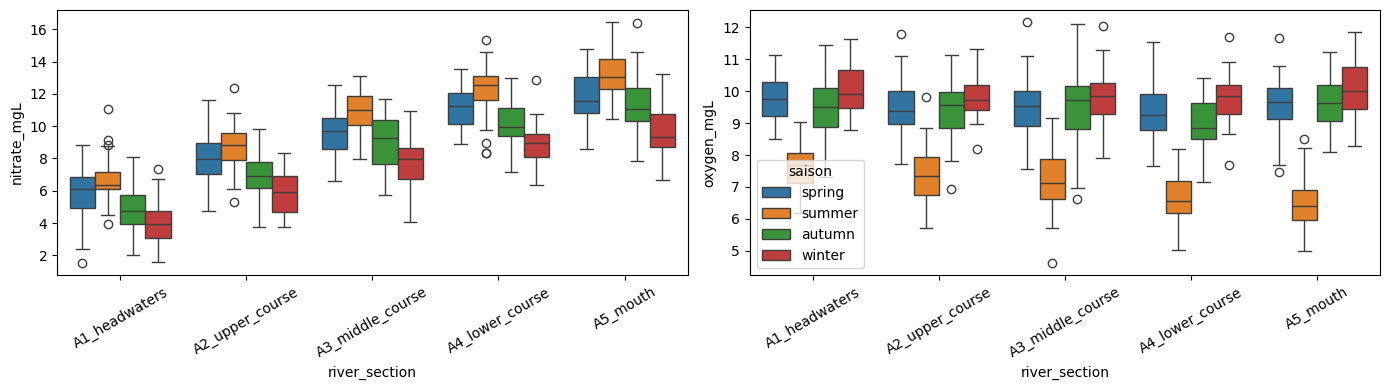

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x="river_section", y="nitrate_mgL", hue="saison", data=df, ax=axes[0])
sns.boxplot(x="river_section", y="oxygen_mgL", hue="saison", data=df, ax=axes[1])

axes[0].get_legend().remove()

axes[0].tick_params(axis="x", rotation=30)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [20]:
for s in ["summer", "autumn"]:
    g = df[df["saison"] == s]
    groups = [g[g["river_section"] == sec]["oxygen_mgL"] for sec in sections]
    print(s)
    for a, b in combinations(range(5), 2):
        res = stats.mannwhitneyu(groups[a], groups[b])
        print(sections[a], "vs", sections[b], round(min(res.pvalue * 10, 1), 4))
    print()

summer
A1_headwaters vs A2_upper_course 1
A1_headwaters vs A3_middle_course 0.1636
A1_headwaters vs A4_lower_course 0.0
A1_headwaters vs A5_mouth 0.0
A2_upper_course vs A3_middle_course 1
A2_upper_course vs A4_lower_course 0.0023
A2_upper_course vs A5_mouth 0.0002
A3_middle_course vs A4_lower_course 0.0241
A3_middle_course vs A5_mouth 0.0014
A4_lower_course vs A5_mouth 1

autumn
A1_headwaters vs A2_upper_course 1
A1_headwaters vs A3_middle_course 1
A1_headwaters vs A4_lower_course 0.0498
A1_headwaters vs A5_mouth 1
A2_upper_course vs A3_middle_course 1
A2_upper_course vs A4_lower_course 0.254
A2_upper_course vs A5_mouth 1
A3_middle_course vs A4_lower_course 0.0948
A3_middle_course vs A5_mouth 1
A4_lower_course vs A5_mouth 0.0091

